# Name : Manthan Madankar
# Class : C2-B2
# Roll no : 16
# ML Practical 5


In [ ]:
from sklearn.model_selection import (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold) # Changed StratifiedGroupKFold to StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score,roc_curve)
import warnings
import seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('diabetes (6) - diabetes (6).csv')
print("\nFirst 5 rows:")
print(df.head())
print("\nLast 5 rows:")
print(df.tail())
print("\nDataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())


First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Last 5 rows:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72            

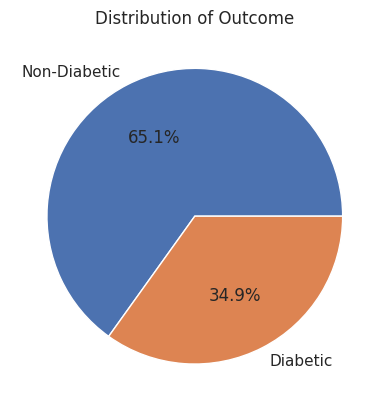

In [ ]:
plt.pie(df['Outcome'].value_counts(),labels=['Non-Diabetic','Diabetic'],autopct='%1.1f%%')
plt.title('Distribution of Outcome')
plt.show()

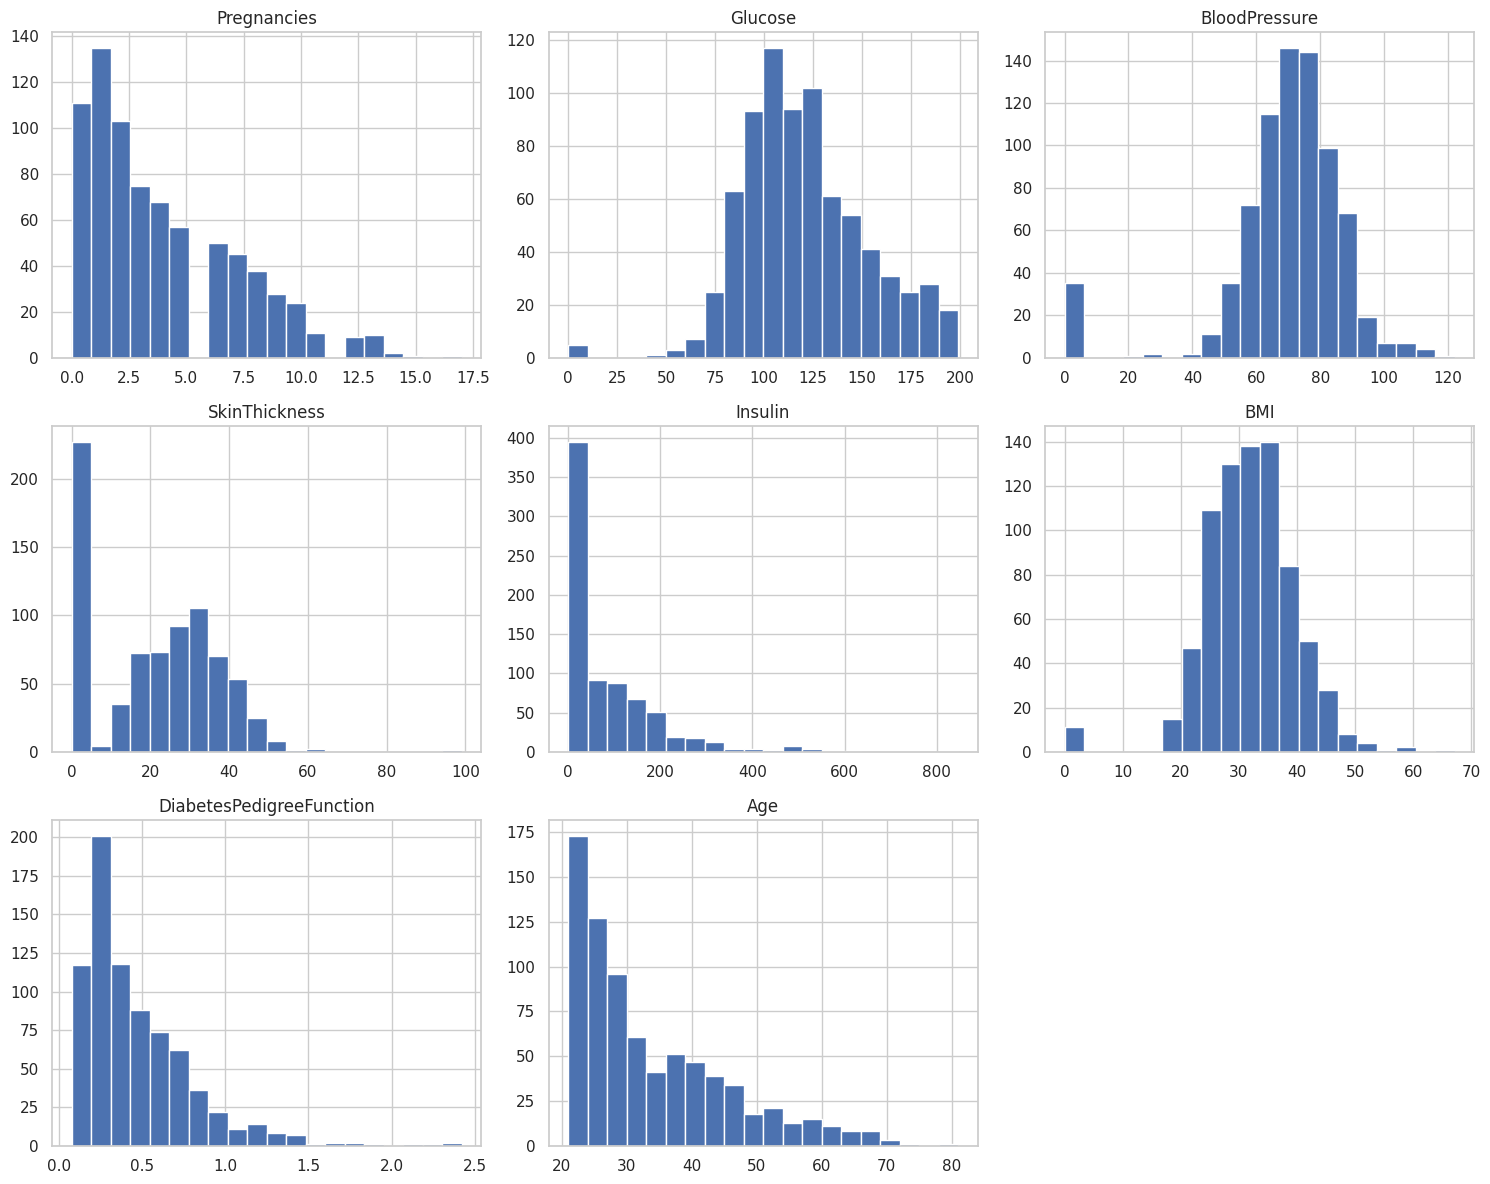

In [ ]:
features=df.drop(columns='Outcome').columns
df[features].hist(figsize=(15,12),bins=20)
plt.title("distribution of diabetes",fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
numeric_cols = features

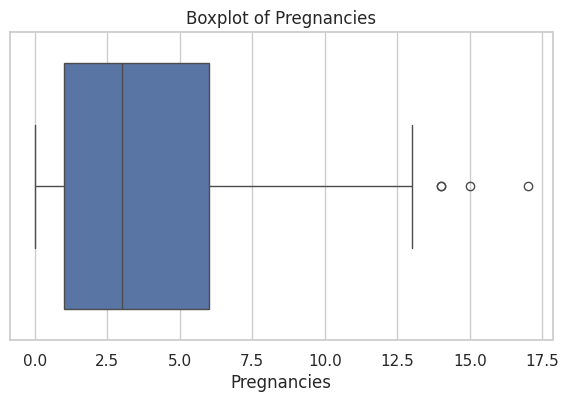

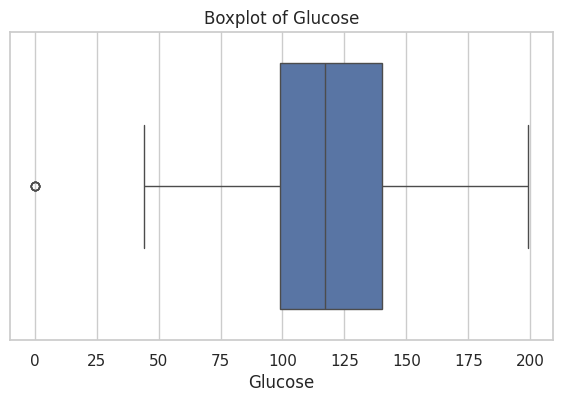

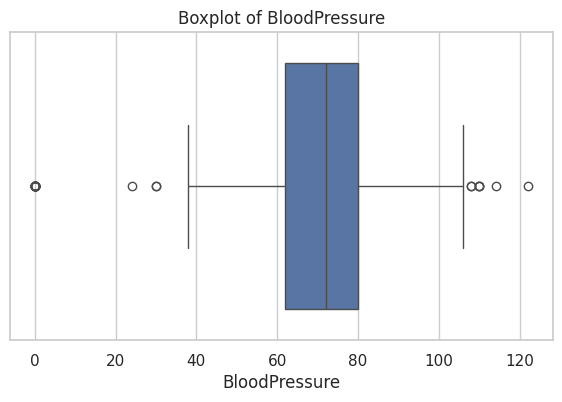

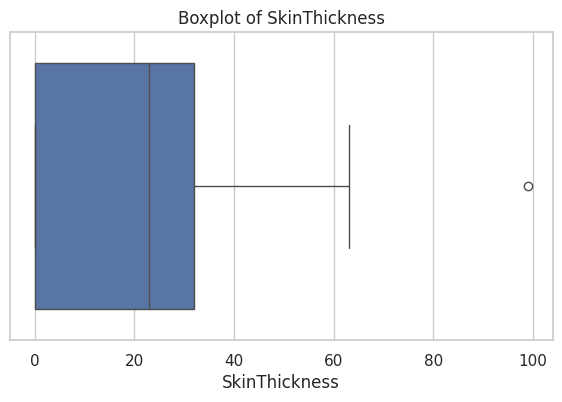

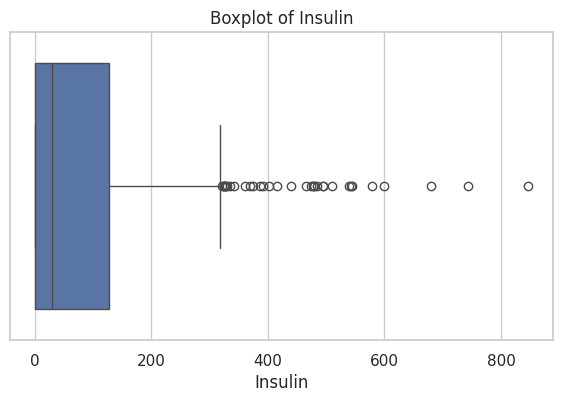

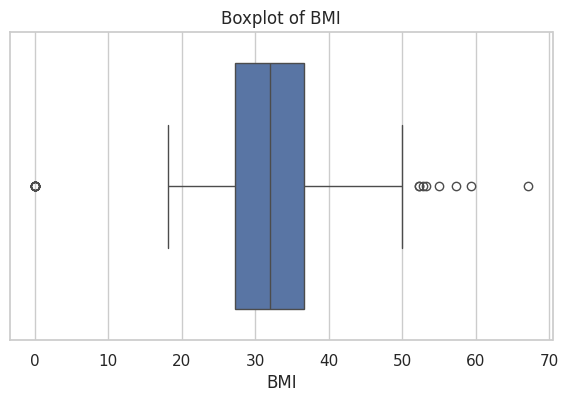

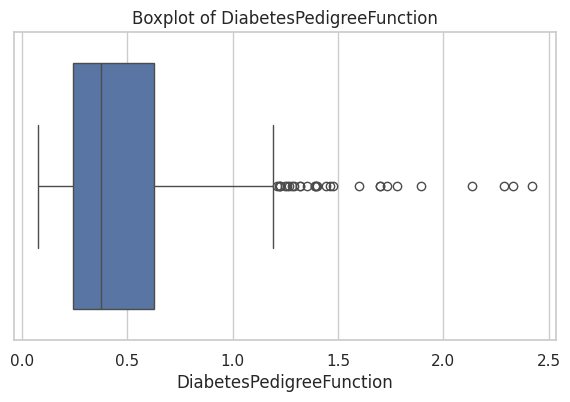

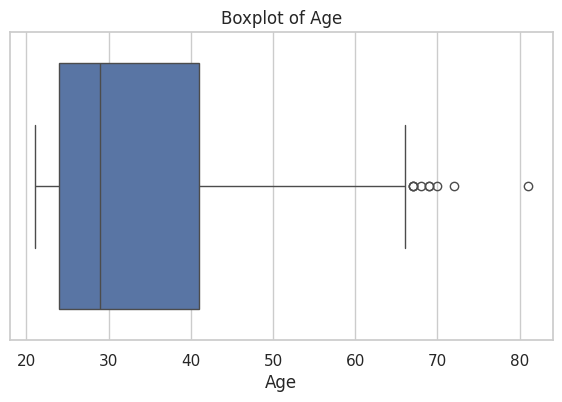

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [ ]:
zero_columns=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts=(df[zero_columns]==0).sum()
print("Number of zeros in each column:")
print(zero_counts)

Number of zeros in each column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [ ]:
df_clean=df.copy()
df_clean[zero_columns]=df_clean[zero_columns].replace(0,np.nan)
print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
for col in zero_columns:
  df_clean[col]=df_clean[col].fillna(df_clean[col].median())
print('Missing values after median imputation:')
print(df_clean.isnull().sum())

Missing values after median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


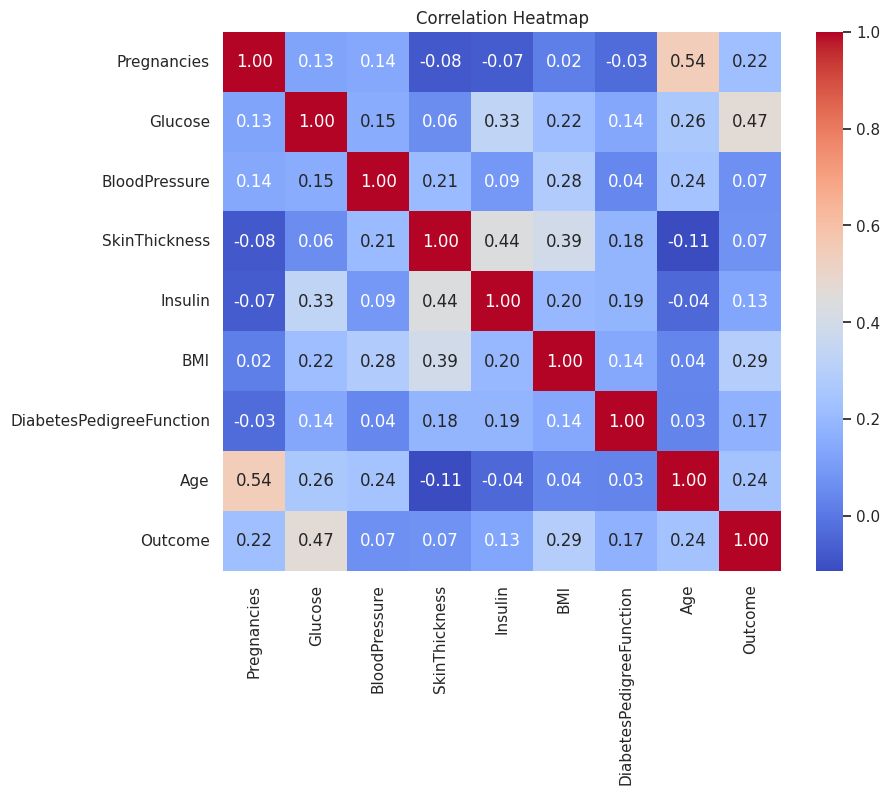

In [ ]:
plt.figure(figsize=(9,7))
corr=df.corr()
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
X=df_clean.drop("Outcome",axis=1)
y=df_clean['Outcome']
print('X shape:',X.shape)
print('y shape:',y.shape)

X shape: (768, 8)
y shape: (768,)


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print('Training sample:',X_train.shape[0])
print('Testing sample:',X_test.shape[0])

Training sample: 614
Testing sample: 154


In [ ]:
print('Training distribution:')
print(y_train.value_counts(normalize=True))
print('Testing distribution:')
print(y_test.value_counts(normalize=True))

Training distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Testing distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [ ]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
comparison=pd.DataFrame({
    'Original mean':X_train.mean(),
    'Original std':X_train.std(),
    'Scaled mean':X_train_scaled.mean(axis=0),
    'Scaled std':X_train_scaled.std(axis=0)
})

In [ ]:
display(comparison)

,Original mean,Original std,Scaled mean,Scaled std
Pregnancies,3.819218,3.314148,-6.943414e-17,1.0
Glucose,121.671010,30.003794,-1.099374e-16,1.0
BloodPressure,72.140065,12.275119,3.095606e-16,1.0
SkinThickness,29.042345,8.891855,-3.471707e-17,1.0
Insulin,137.705212,78.764767,-4.339634e-18,1.0
BMI,32.446743,6.824142,-1.148556e-15,1.0
DiabetesPedigreeFunction,0.477428,0.330300,-1.099374e-16,1.0
Age,33.366450,11.833438,-1.084908e-16,1.0


In [ ]:
K=5

In [ ]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,y_train)

KNeighborsClassifier()

In [ ]:
y_pred=knn.predict(X_test_scaled)
print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [ ]:
y_prob=knn.predict_proba(X_test_scaled)[:,1]
print(y_prob[:20])

[0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 1.  0.2]


In [ ]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.7532467532467533


In [ ]:
precision=precision_score(y_test,y_pred)
print("Precision:",precision)

Precision: 0.66


In [ ]:
recall=recall_score(y_test,y_pred)
print("Recall:",recall)

Recall: 0.6111111111111112


In [ ]:
f1=f1_score(y_test,y_pred)
print("F1 Score:",f1)

F1 Score: 0.6346153846153846


In [ ]:
print(classification_report(y_test,y_pred,target_names=['No Diabetes','Diabetes']))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [ ]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[83 17]
 [21 33]]


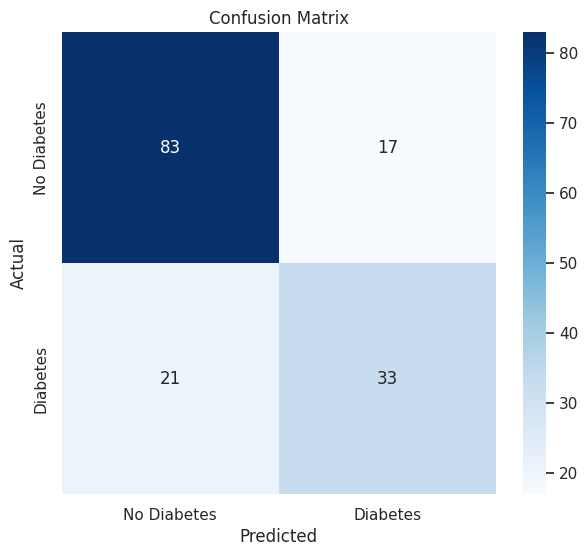

In [ ]:
plt.figure(figsize=(7,6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['No Diabetes','Diabetes'],yticklabels=['No Diabetes','Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
k_values=range(1,31)
train_accuracy=[]
test_accuracy=[]
for k in k_values:
  model=KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train_scaled,y_train)
  train_accuracy.append(model.score(X_train_scaled,y_train))
  test_accuracy.append(model.score(X_test_scaled,y_test))

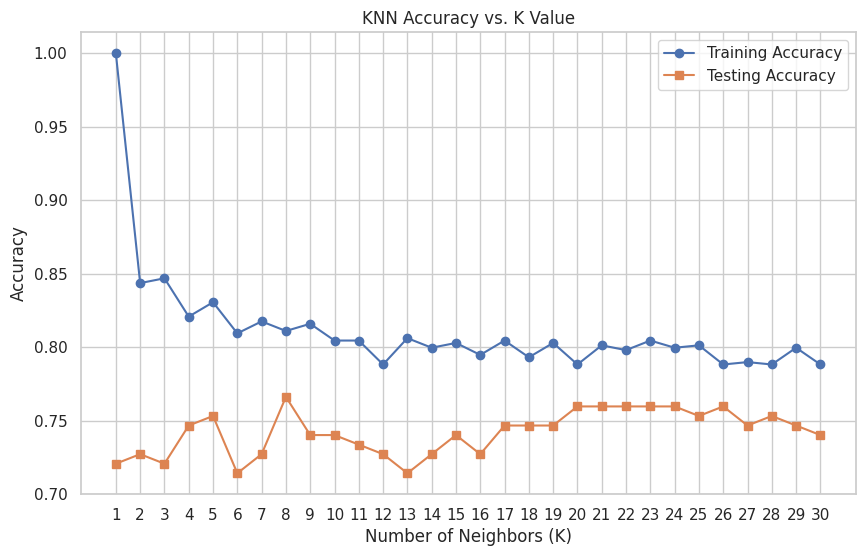

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(k_values,train_accuracy,marker='o',label='Training Accuracy')
plt.plot(k_values,test_accuracy,marker='s',label='Testing Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs. K Value')
plt.xticks(k_values)
plt.legend()
plt.show()

In [ ]:
best_k_accuracy=k_values[np.argmax(test_accuracy)]
best_accuracy=max(test_accuracy)
print("Best K Value:",best_k_accuracy)
print("Best test Accuracy:",best_accuracy)

Best K Value: 8
Best test Accuracy: 0.7662337662337663


In [ ]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_scores=[]
for k in range(1,31):
  model=KNeighborsClassifier(n_neighbors=k)
  scores=cross_val_score(model,X_train_scaled,y_train,cv=cv,scoring='accuracy')
  cv_scores.append(scores.mean())

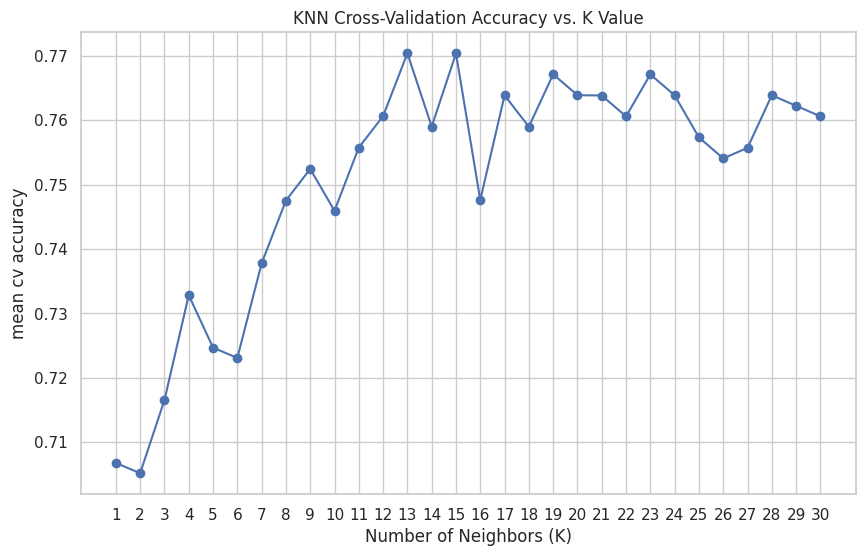

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(range(1,31),cv_scores,marker='o')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('mean cv accuracy')
plt.title('KNN Cross-Validation Accuracy vs. K Value')
plt.xticks(range(1,31))
plt.show()

In [ ]:
best_k_cv=np.argmax(cv_scores)+1
print('Best K based on cross validation:',best_k_cv)
print('Best cv accuracy:',max(cv_scores))

Best K based on cross validation: 13
Best cv accuracy: 0.7703718512594963


In [ ]:
param_grid={'n_neighbors':list(range(3,31,2)),'weights':['uniform','distance'],
            'metric':['euclidean','manhattan','minkowski'],
            'p':[1,2]}
grid_search=GridSearchCV(estimator=KNeighborsClassifier(),param_grid=param_grid,cv=5,scoring='accuracy')
grid_search.fit(X_train_scaled,y_train)
print('Grid search completed.')
print('Best parameters:')
print(grid_search.best_params_)
print('Best Cross-Validation Accuracy:',grid_search.best_score_)

Grid search completed.
Best parameters:
{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}
Best Cross-Validation Accuracy: 0.7769025723044115
